Using local AerSimulator / AerSampler
Number of feasible solutions = 3.0
CPLEX solution: [0.0, 1.0, 1.0, 0.0, 0.0, 1.0]


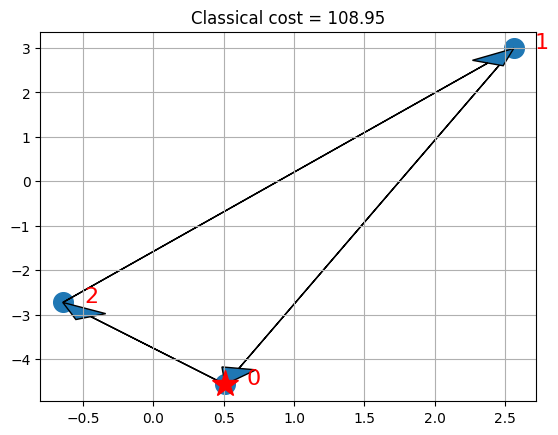

Binary cost: 108.95095265873533 Classical cost: 108.95095265873083
Binary formulation is correct
Quantum solution: [0. 1. 1. 0. 0. 1.]
Quantum cost: 108.95095265873533


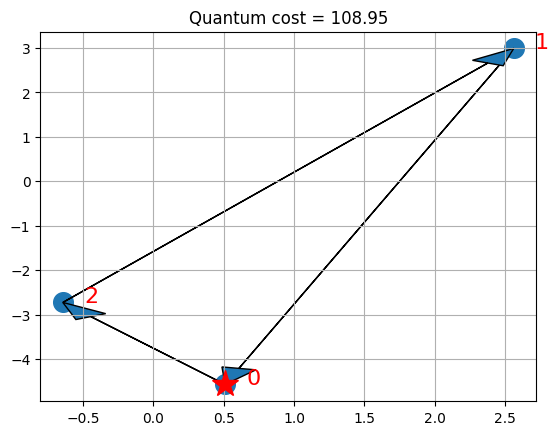

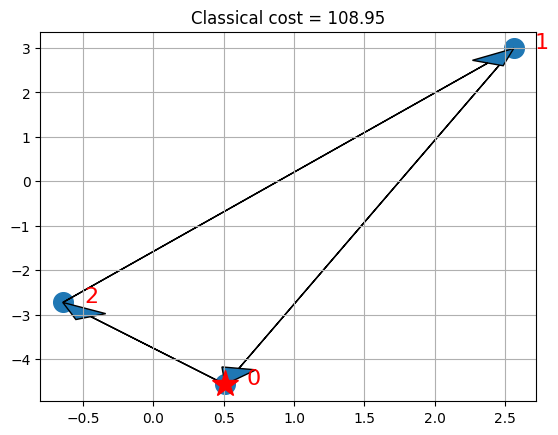

In [14]:
# ===== 0. Setup: Local or IBM =====
import warnings
warnings.filterwarnings("ignore")

use_ibm = False
try:
    from qiskit_ibm_runtime import QiskitRuntimeService, Sampler as IBMSampler
    try:
        service = QiskitRuntimeService()
        backend = service.backend("ibmq_qasm_simulator")
        sampler = IBMSampler(session=service)
        use_ibm = True
        print("Using IBM runtime:", backend.name())
    except Exception:
        use_ibm = False
except Exception:
    use_ibm = False

if not use_ibm:
    try:
        from qiskit_aer import AerSimulator
        from qiskit_aer.primitives import Sampler as AerSampler
        simulator = AerSimulator()
        sampler = AerSampler()
        backend = simulator
        print("Using local AerSimulator / AerSampler")
    except Exception:
        from qiskit import Aer
        backend = Aer.get_backend("aer_simulator")
        sampler = None
        print("Using qiskit.Aer.get_backend('aer_simulator') (sampler not available)")

# Standard imports
import numpy as np
import matplotlib.pyplot as plt
import math
import cplex
from cplex.exceptions import CplexError

from qiskit.utils import algorithm_globals
from qiskit.algorithms.minimum_eigensolvers import SamplingVQE
from qiskit.algorithms.optimizers import SPSA
from qiskit.circuit.library import RealAmplitudes
from qiskit.primitives import Sampler
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.algorithms import MinimumEigenOptimizer

# ===== 1. Problem initialization =====
n = 3  # nodes including depot
K = 1  # number of vehicles

class Initializer:
    def __init__(self, n):
        self.n = n

    def generate_instance(self):
        np.random.seed(1543)
        xc = (np.random.rand(self.n) - 0.5) * 10
        yc = (np.random.rand(self.n) - 0.5) * 10
        instance = np.zeros([self.n, self.n])
        for i in range(self.n):
            for j in range(i + 1, self.n):
                instance[i, j] = (xc[i] - xc[j]) ** 2 + (yc[i] - yc[j]) ** 2
                instance[j, i] = instance[i, j]
        return xc, yc, instance

initializer = Initializer(n)
xc, yc, instance = initializer.generate_instance()

# ===== 2. Classical Optimizer =====
class ClassicalOptimizer:
    def __init__(self, instance, n, K):
        self.instance = instance
        self.n = n
        self.K = K

    def compute_allowed_combinations(self):
        f = math.factorial
        return f(self.n) / f(self.K) / f(self.n - self.K)

    def cplex_solution(self):
        n, K, instance = self.n, self.K, self.instance
        my_obj = list(instance.reshape(1, n**2)[0]) + [0.0] * (n - 1)
        my_ub = [1] * (n**2 + n - 1)
        my_lb = [0] * n**2 + [0.1] * (n - 1)
        my_ctype = "I" * n**2 + "C" * (n - 1)
        my_rhs = 2 * ([K] + [1] * (n - 1)) + [0.9] * ((n - 1) ** 2 - (n - 1)) + [0] * n
        my_sense = "E" * (2 * n) + "L" * ((n - 1) ** 2 - (n - 1)) + "E" * n
        try:
            prob = cplex.Cplex()
            self.populatebyrow(prob, my_obj, my_ub, my_lb, my_ctype, my_sense, my_rhs)
            prob.solve()
        except CplexError as exc:
            print(exc)
            return None, None
        x = np.array(prob.solution.get_values())
        cost = prob.solution.get_objective_value()
        return x, cost

    def populatebyrow(self, prob, obj, ub, lb, ctype, sense, rhs):
        n = self.n
        prob.objective.set_sense(prob.objective.sense.minimize)
        prob.variables.add(obj=obj, lb=lb, ub=ub, types=ctype)
        prob.set_log_stream(None)
        prob.set_error_stream(None)
        prob.set_warning_stream(None)
        prob.set_results_stream(None)
        rows = []
        for i in range(n):
            rows.append([[j for j in range(n * i, n * (i + 1))], [1]*n])
        for i in range(n):
            rows.append([[j for j in range(i, n**2, n)], [1]*n])
        # Sub-tour elimination constraints
        for i in range(n):
            for j in range(n):
                if i != j and i*j > 0:
                    rows.append([[i + j*n, n**2 + i - 1, n**2 + j - 1], [1, 1, -1]])
        for i in range(n):
            rows.append([[i*(n+1)], [1]])
        prob.linear_constraints.add(lin_expr=rows, senses=sense, rhs=rhs)

classical_optimizer = ClassicalOptimizer(instance, n, K)
print("Number of feasible solutions =", classical_optimizer.compute_allowed_combinations())

x = None
z = None
try:
    x, classical_cost = classical_optimizer.cplex_solution()
    z = [x[i] for i in range(n**2) if i // n != i % n]
    print("CPLEX solution:", z)
except:
    print("CPLEX may be missing.")

# ===== 3. Visualization =====
def visualize_solution(xc, yc, x, C, n, K, title):
    plt.figure()
    plt.scatter(xc, yc, s=200)
    for i, (xx, yy) in enumerate(zip(xc, yc)):
        plt.annotate(i, (xx + 0.15, yy), size=16, color="r")
    plt.plot(xc[0], yc[0], "r*", ms=20)
    plt.grid()
    for i in range(n**2):
        if x[i] > 0:
            ix, iy = i // n, i % n
            plt.arrow(xc[ix], yc[ix], xc[iy]-xc[ix], yc[iy]-yc[ix], length_includes_head=True, head_width=0.25)
    plt.title(f"{title} cost = {C:.2f}")
    plt.show()

if x is not None:
    visualize_solution(xc, yc, x, classical_cost, n, K, "Classical")

# ===== 4. Quantum Optimizer =====
class QuantumOptimizer:
    def __init__(self, instance, n, K):
        self.instance = instance
        self.n = n
        self.K = K

    def binary_representation(self, x_sol=0):
        instance, n, K = self.instance, self.n, self.K
        A = np.max(instance) * 100
        instance_vec = instance.reshape(n**2)
        w_list = [instance_vec[i] for i in range(n**2) if instance_vec[i] > 0]
        w = np.zeros(n * (n - 1))
        for i in range(len(w_list)):
            w[i] = w_list[i]
        Id_n, Im_n_1 = np.eye(n), np.ones([n-1, n-1])
        Iv_n_1, Iv_n = np.ones(n), np.ones(n-1)
        Iv_n_1[0] = 0
        neg_Iv_n_1 = 1 - Iv_n_1
        v = np.zeros([n, n*(n-1)])
        for i in range(n):
            count = i-1
            for j in range(n*(n-1)):
                if j//(n-1) == i: count = i
                if j//(n-1) != i and j%(n-1) == count: v[i,j] = 1
        vn = np.sum(v[1:], axis=0)
        Q = A * (np.kron(Id_n, Im_n_1) + np.dot(v.T, v))
        g = w - 2*A*(np.kron(Iv_n_1, Iv_n) + vn.T) - 2*A*K*(np.kron(neg_Iv_n_1, Iv_n) + v[0].T)
        c = 2*A*(n-1) + 2*A*K**2
        try:
            fun = lambda x: np.dot(np.around(x), np.dot(Q, np.around(x))) + np.dot(g, np.around(x)) + c
            cost = fun(x_sol)
        except:
            cost = 0
        return Q, g, c, cost

    def construct_problem(self, Q, g, c):
        qp = QuadraticProgram()
        for i in range(n*(n-1)):
            qp.binary_var(str(i))
        qp.objective.quadratic = Q
        qp.objective.linear = g
        qp.objective.constant = c
        return qp

    def solve_problem(self, qp):
        algorithm_globals.random_seed = 10598
        vqe = SamplingVQE(sampler=sampler, optimizer=SPSA(), ansatz=RealAmplitudes())
        optimizer = MinimumEigenOptimizer(min_eigen_solver=vqe)
        result = optimizer.solve(qp)
        _, _, _, level = self.binary_representation(x_sol=result.x)
        return result.x, level

quantum_optimizer = QuantumOptimizer(instance, n, K)

try:
    if z is not None:
        Q, g, c, binary_cost = quantum_optimizer.binary_representation(x_sol=z)
        print("Binary cost:", binary_cost, "Classical cost:", classical_cost)
        if abs(binary_cost-classical_cost) < 0.01:
            print("Binary formulation is correct")
        else:
            print("Binary formulation mismatch")
    else:
        Q, g, c, binary_cost = quantum_optimizer.binary_representation()
        print("Binary cost:", binary_cost)
except NameError:
    print("Run classical optimizer first.")

qp = quantum_optimizer.construct_problem(Q, g, c)
quantum_solution, quantum_cost = quantum_optimizer.solve_problem(qp)
print("Quantum solution:", quantum_solution)
print("Quantum cost:", quantum_cost)

# Map quantum solution to full x matrix
x_quantum = np.zeros(n**2)
k = 0
for i in range(n**2):
    if i // n != i % n:
        x_quantum[i] = quantum_solution[k]
        k += 1

# Visualize quantum solution
visualize_solution(xc, yc, x_quantum, quantum_cost, n, K, "Quantum")

# Compare with classical solution
if x is not None:
    visualize_solution(xc, yc, x, classical_cost, n, K, "Classical")
